# 4.3 · LightGBM 树模型：量化选股的主力

> 工业界多因子选股用得最多的不是线性模型，而是**梯度提升树（GBDT），尤其是 LightGBM**。
> 它能自动捕捉**非线性关系和因子交互**，对共线性、缺失值、异常值稳健，且不需要标准化。
> 本节理解决策树与 Boosting，并用 LightGBM 训练、查看特征重要性。

## 一、决策树的原理

决策树通过**递归地按特征阈值分裂**样本：
- 在每个节点选择一个特征和一个阈值，把样本分成两组，使分裂后两组的**标签更"纯"**（信息增益最大，如方差下降最多）；
- 不断分裂直到达到停止条件（最大深度、叶子最少样本数等）；
- 每个叶子给出一个预测值（该叶子样本标签的均值）。

树天然能表达**非线性（不同区间不同规则）和特征交互（多层分裂）**。

## 二、集成：从一棵树到一片森林

单棵树容易过拟合，集成方法组合多棵树：
- **Bagging（随机森林）**：并行训练多棵树、每棵用随机子样本和特征，投票/平均——降低方差；
- **Boosting（GBDT / XGBoost / LightGBM）**：串行训练，**每棵新树拟合前面所有树的残差（负梯度）**，逐步降低偏差。

**GBDT（梯度提升树）**：预测值 = 所有树的累加；每轮新增一棵树去拟合当前的预测误差。
- **XGBoost**：GBDT 的高效工程实现（二阶导数、正则）；
- **LightGBM**：更快、更省内存（直方图算法、leaf-wise 生长），量化中最常用。

## 三、用 LightGBM 训练（rank 标签）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from model_lab.data import build_panel, split_by_date, predict_ic
from model_lab.linear import rank_label
from model_lab.tree import fit_lgb, feature_importance
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
df = build_panel(close, F['$volume'].unstack('instrument'),
                 F['$mkt_cap_ard'].unstack('instrument'),
                 F['$pe_ttm'].unstack('instrument'),
                 F['$pb_lf'].unstack('instrument'), 1)
tr, va, te = split_by_date(df, '2022-12-31', '2023-12-31')
feat = [c for c in df.columns if c != 'label']
tr_r, va_r = rank_label(tr), rank_label(va)

lgbm = fit_lgb(tr_r, va_r, feat, label='y_rank')
pred = pd.Series(lgbm.predict(te[feat]), index=te.index)
ic = predict_ic(pred, te['label'])
print('LightGBM 最佳树数: %d' % lgbm.best_iteration_)
print('测试集 IC %.4f  IR %.4f  胜率 %.3f' % (ic.mean(), ic.mean()/ic.std(), (ic>0).mean()))

[19988:MainThread](2026-10-30 01:25:27,627) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[19988:MainThread](2026-10-30 01:25:29,026) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[19988:MainThread](2026-10-30 01:25:29,027) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[16]	valid_0's l2: 0.0832743


LightGBM 最佳树数: 16
测试集 IC 0.0315  IR 0.1733  胜率 0.573


## 四、特征重要性：模型最依赖哪些因子

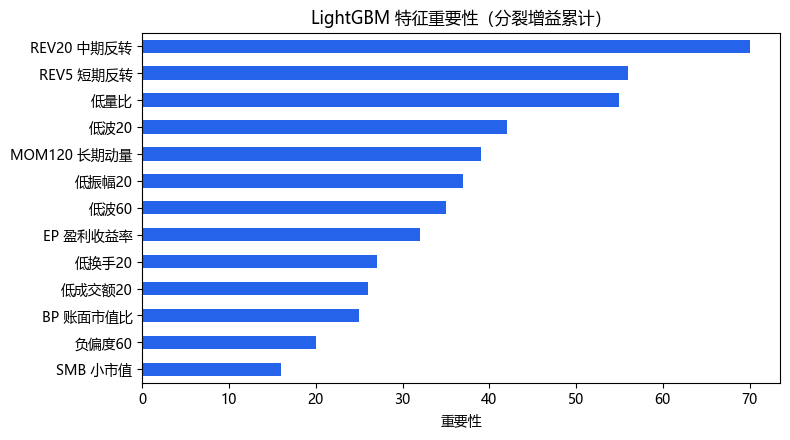

REV20 中期反转     70
REV5 短期反转      56
低量比            55
低波20           42
MOM120 长期动量    39
低振幅20          37
低波60           35
EP 盈利收益率       32
低换手20          27
低成交额20         26
BP 账面市值比       25
负偏度60          20
SMB 小市值        16
dtype: int32


In [2]:
imp = feature_importance(lgbm, feat)
plt.figure(figsize=(8, 4.5))
imp.sort_values().plot(kind='barh', color='#2563eb')
plt.title('LightGBM 特征重要性（分裂增益累计）'); plt.xlabel('重要性')
plt.tight_layout(); plt.show()
print(imp.round(0))

## 五、与线性模型对比

              IC      IR
等权        0.0397  0.1462
Ridge     0.0280  0.1379
LightGBM  0.0315  0.1733


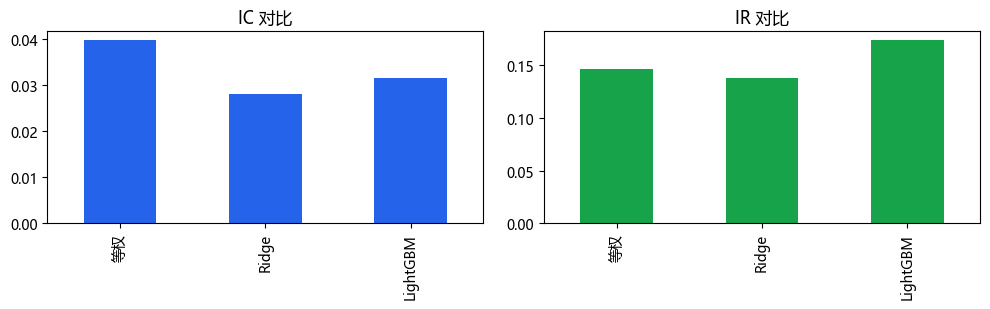

In [3]:
from model_lab.linear import fit_linear
equal = te[feat].mean(axis=1)
ic_eq = predict_ic(equal, te['label'])
ridge = fit_linear(tr, feat, 'ridge', 1.0, use_rank_label=True)
ic_rd = predict_ic(pd.Series(ridge.predict(te[feat]), index=te.index), te['label'])
rows = {
    '等权': (ic_eq.mean(), ic_eq.mean()/ic_eq.std()),
    'Ridge': (ic_rd.mean(), ic_rd.mean()/ic_rd.std()),
    'LightGBM': (ic.mean(), ic.mean()/ic.std()),
}
cmp = pd.DataFrame(rows, index=['IC','IR']).T
print(cmp.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10,3.2))
cmp['IC'].plot(kind='bar', ax=ax[0], color='#2563eb'); ax[0].set_title('IC 对比')
cmp['IR'].plot(kind='bar', ax=ax[1], color='#16a34a'); ax[1].set_title('IR 对比')
plt.tight_layout(); plt.show()

## 六、超参数与防过拟合

关键超参数：
- `num_leaves` / `max_depth`：叶子数/深度，越大越复杂、越易过拟合；
- `learning_rate`：学习率（小则慢但稳）；
- `n_estimators` + **early stopping**：用验证集自动决定树数；
- `min_child_samples`：叶子最少样本数（调大防过拟合）；
- `subsample`（行采样）、`colsample_bytree`（特征采样）：增加随机性。

> 在沪深300、弱信号、次日预测下，模型往往**几十棵树就 early stop**——说明此时简单规律就够，过度复杂反而过拟合。树模型的真正优势在更大股票池、更丰富特征时更明显。

## 七、小结与面试要点

- 决策树按特征阈值递归分裂，捕捉非线性；GBDT 串行拟合残差，LightGBM 是高效实现。
- 树模型对共线性、缺失、异常值稳健，无需标准化，是量化选股主力。
- 用截面 rank 标签 + 验证集 early stopping；通过 num_leaves、min_child_samples、采样防过拟合。
- 弱信号下简单模型（等权）IC 不弱，树模型 IR 更稳；优势在更大数据量时显现。

**面试高频：**
- 为什么量化选股常用 LightGBM？（答：非线性、因子交互、对共线性/缺失稳健、不需标准化）
- Bagging 和 Boosting 的区别？（答：Bagging 并行降方差，Boosting 串行拟合残差降偏差）
- 怎么防 LightGBM 过拟合？（答：限叶子/深度、early stop、增大 min_child_samples、行列采样）
- 树模型为什么不需要特征标准化？（答：分裂只看阈值顺序，与尺度无关）

## 动手练习
1. 调 num_leaves=8 / 64，观察 IC 与最佳树数；
2. 用原始标签训练，对比 rank 标签；
3. 画出单棵树的结构（可用 lgb.plot_tree），理解分裂规则。

---
下一节 **4.4 深度学习模型：LSTM、GRU、ALSTM、Transformer、GNN**。